# Протокол виконання лабораторної роботи №4
**Тема:** Support Vector Machine (SVM)
**Мета:** Реалізувати процедуру класифікації з використанням методу опорних векторів (SVM) бібліотеки scikit-learn та провести аналіз результатів.

## 1. Підготовка даних
Завантажуємо локальний набір даних, відбираємо перші дві числові ознаки для подальшої візуалізації у 2D просторі та стандартизуємо їх.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Завантаження даних
file_path = 'data/data.csv'
df = pd.read_csv(file_path)

# Відбір 2 числових ознак (пропускаємо id та текстовий діагноз)
X = df.iloc[:, 2:4].values 
y_text = df.iloc[:, 1].values 

# Бінаризація цільової змінної ('M' -> 1, 'B' -> 0)
y = np.where(y_text == 'M', 1, 0)

# Розбиття на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Стандартизація даних (важливо для SVM)
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)

## 2. Реалізація класифікатору (Ядерний метод SVM)
Використовуємо радіально-базисну функцію (RBF) для вирішення нелінійної задачі класифікації.

In [4]:
# Навчання моделі з ядром RBF
svm = SVC(kernel='rbf', random_state=42, gamma=0.2, C=10.0)
svm.fit(X_train_std, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10.0
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


## 3. Візуалізація результатів класифікації
Будуємо графік розділювальної поверхні та виділяємо опорні вектори.

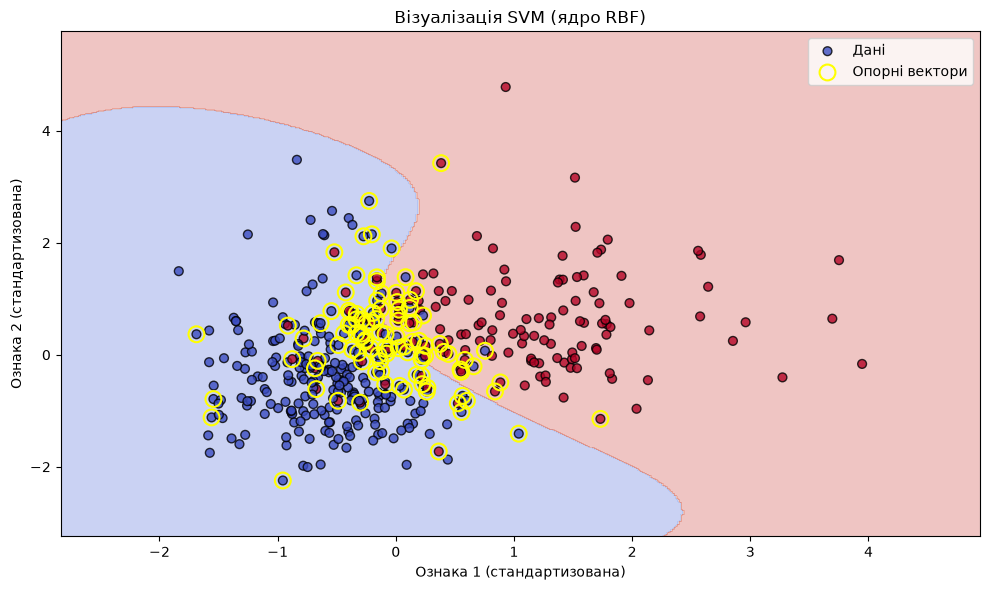

In [5]:
def plot_decision_regions(X, y, classifier, title="SVM Decision Regions"):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    
    Z = classifier.predict(np.array([xx.ravel(), yy.ravel()]).T)
    Z = Z.reshape(xx.shape)
    
    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, alpha=0.8, edgecolors='k', cmap='coolwarm', s=40, label='Дані')
    
    # Виділення опорних векторів жовтим кольором
    plt.scatter(classifier.support_vectors_[:, 0], classifier.support_vectors_[:, 1], 
                s=130, linewidth=1.5, facecolors='none', edgecolors='yellow', label='Опорні вектори')
    
    plt.title(title)
    plt.xlabel('Ознака 1 (стандартизована)')
    plt.ylabel('Ознака 2 (стандартизована)')
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()

# Візуалізація на навчальній вибірці
plot_decision_regions(X_train_std, y_train, classifier=svm, title="Візуалізація SVM (ядро RBF)")

## 4. Аналіз результатів

### 4.1. Вибір параметрів ядра та їх обґрунтування
Оскільки класи на графіку суттєво перекриваються і не можуть бути ідеально розділені прямою лінією, було обрано **нелінійне ядро RBF (радіально-базисна функція)**. Це ядро проектує дані у простір вищої розмірності, дозволяючи побудувати складну нелінійну розділювальну поверхню.

* **Параметр `C = 10.0` (Регуляризація):** Задає штраф за неправильну класифікацію. Значення 10.0 є збалансованим компромісом: воно дозволяє створити достатньо строгу межу для правильної класифікації більшості точок, але при цьому допускає деякі помилки (soft margin) у зоні сильного перекриття класів, щоб уникнути перенавчання.
* **Параметр `gamma = 0.2`:** Визначає радіус впливу кожного навчального прикладу. Значення 0.2 є відносно невеликим, що робить розділювальну межу більш плавною та широкою. Якби значення `gamma` було занадто великим, межа огинала б кожну окрему точку, що призвело б до жорсткого перенавчання.

In [6]:
# Розрахунок точності
train_acc = accuracy_score(y_train, svm.predict(X_train_std))
test_acc = accuracy_score(y_test, svm.predict(X_test_std))

print(f"Точність на навчальній вибірці: {train_acc:.3f} ({train_acc * 100:.1f}%)")
print(f"Точність на тестовій вибірці: {test_acc:.3f} ({test_acc * 100:.1f}%)")

Точність на навчальній вибірці: 0.902 (90.2%)
Точність на тестовій вибірці: 0.918 (91.8%)


### 4.2. Оцінка помилок на навчальній та тестовій вибірках
* **Навчальна вибірка:** Точність становить **90.2%** (помилка 9.8%). Модель добре засвоїла закономірності у даних, незважаючи на значне перекриття класів у 2D просторі.
* **Тестова вибірка:** Точність становить **91.8%** (помилка 8.2%). 

**Висновок:** Точність на тестовій вибірці виявилася навіть трохи вищою за точність на навчальній. Це є чудовим індикатором того, що модель **не перенавчилася (відсутній overfitting)**. Класифікатор SVM з поточними гіперпараметрами має високу здатність до генералізації (узагальнення) на нових, раніше не бачених даних. Наявність значної кількості опорних векторів (виділених жовтим на графіку) у прикордонній зоні підтверджує, що алгоритм успішно сформував оптимальну "м'яку" маржу між класами.